In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
#
# deque: a double-ended queue — we use it for Breadth-First Search (BFS).
# BFS visits nodes level by level (root first, then all depth-1 nodes, then
# all depth-2 nodes, etc.).  That is exactly what the exercise asks for when
# printing the tree structure.
#
# sklearn is ONLY used at the very end to cross-check our own implementation.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from collections import deque
from numpy.random import default_rng

# sklearn: for final comparison only
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score

matplotlib.rcParams['figure.dpi'] = 120
rng = default_rng(42)
print('All imports ready.')

All imports ready.


In [2]:
# ── Load Iris dataset ─────────────────────────────────────────────────────────
#
# The file has NO header line.  Columns are:
#   sepal_length, sepal_width, petal_length, petal_width, class
# The last line is blank, so we use dropna() to remove it.
#
# We map class strings → integers so our tree can work with numpy arrays:
#   Iris-setosa     → 0
#   Iris-versicolor → 1
#   Iris-virginica  → 2

iris_df = pd.read_csv(
    'iris/iris.data',
    header=None,
    names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
).dropna()

feature_names = ['sepal length', 'sepal width', 'petal length', 'petal width']
class_names   = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
class_to_int  = {name: i for i, name in enumerate(class_names)}

X = iris_df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].to_numpy(dtype=float)
y = iris_df['class'].map(class_to_int).to_numpy(dtype=int)

n_classes = len(class_names)

print(f'Shape: X={X.shape}, y={y.shape}')
print(f'Features: {feature_names}')
print(f'Classes:  {class_names}')
print(f'Class distribution: {np.bincount(y)}  (each=50 → balanced)')
print(f'\nFirst 5 rows:')
print(iris_df.head())

Shape: X=(150, 4), y=(150,)
Features: ['sepal length', 'sepal width', 'petal length', 'petal width']
Classes:  ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Class distribution: [50 50 50]  (each=50 → balanced)

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


In [3]:
# ── Exercise 1: 70 / 30 train-test split ──────────────────────────────────────
#
# stratify=y ensures both sets keep the same class ratio (50/50/50 → 35/35/35
# in train, 15/15/15 in test).  Without stratify, a random split could put
# almost all of one class in training and none in test.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Train class counts: {np.bincount(y_train)}')
print(f'Test  class counts: {np.bincount(y_test)}')

# NOTE: No normalisation needed for decision trees!
# Trees split on thresholds (feature <= t), so the absolute scale of features
# does not matter.  Whether petal_length is in cm or mm, the same split
# will be found.

Train: (105, 4)  |  Test: (45, 4)
Train class counts: [35 35 35]
Test  class counts: [15 15 15]


In [4]:
# ── Impurity functions ────────────────────────────────────────────────────────
#
# CROSS ENTROPY (Shannon entropy, base-2):
#   H(S) = -Σk  pk · log2(pk)
#
#   pk = fraction of samples in S belonging to class k.
#   Convention: 0 · log2(0) = 0  (a class that is absent contributes nothing).
#
#   H=0 when all samples are the same class (perfectly pure).
#   H=log2(K) when all K classes are equally represented (maximum disorder).
#   For K=3 classes, maximum H = log2(3) ≈ 1.585 bits.
#
# GINI INDEX:
#   G(S) = 1 - Σk pk²
#
#   Same idea as entropy but using squared probabilities instead of log.
#   G=0 when pure, G=1-1/K at maximum impurity.
#   For K=3: max G = 1 - 3·(1/3)² = 1 - 1/3 ≈ 0.667.
#
# INFORMATION GAIN (applies to both criteria):
#   IG(S, feature, threshold) = Impurity(S)
#                             - (nL/n)·Impurity(SL)
#                             - (nR/n)·Impurity(SR)
#
#   This is the reduction in impurity when we split S into left (SL) and
#   right (SR) subsets.  Higher IG = better split.

def cross_entropy(y, n_classes):
    """H(S) = -Σk pk·log2(pk), with 0·log2(0) := 0."""
    if len(y) == 0:
        return 0.0
    H = 0.0
    for k in range(n_classes):
        pk = np.sum(y == k) / len(y)
        if pk > 0:
            H -= pk * np.log2(pk)
    return H

def gini_index(y, n_classes):
    """G(S) = 1 - Σk pk²."""
    if len(y) == 0:
        return 0.0
    G = 1.0
    for k in range(n_classes):
        pk = np.sum(y == k) / len(y)
        G -= pk ** 2
    return G

def impurity_fn(y, n_classes, criterion):
    """Dispatcher: entropy or gini."""
    if criterion == 'entropy':
        return cross_entropy(y, n_classes)
    if criterion == 'gini':
        return gini_index(y, n_classes)
    raise ValueError(f'Unknown criterion: {criterion}')

# Quick sanity check
y_all_same  = np.array([0, 0, 0])           # perfectly pure
y_balanced  = np.array([0, 1, 2])           # maximally impure (3 classes)
print(f'Entropy  (pure):     {cross_entropy(y_all_same, 3):.4f}  ← should be 0.0')
print(f'Entropy  (balanced): {cross_entropy(y_balanced, 3):.4f}  ← should be log2(3) = 1.585')
print(f'Gini     (pure):     {gini_index(y_all_same, 3):.4f}  ← should be 0.0')
print(f'Gini     (balanced): {gini_index(y_balanced, 3):.4f}  ← should be 0.667')

Entropy  (pure):     0.0000  ← should be 0.0
Entropy  (balanced): 1.5850  ← should be log2(3) = 1.585
Gini     (pure):     0.0000  ← should be 0.0
Gini     (balanced): 0.6667  ← should be 0.667


In [5]:
# ── TreeNode class ────────────────────────────────────────────────────────────
#
# Each node of the tree stores:
#   feature_idx, threshold  → the split rule: go left if x[feature_idx] <= threshold
#   left, right             → child nodes (None for leaves)
#   is_leaf                 → True if this node makes the final prediction
#   class_label             → predicted class (argmax of class_probs)
#   class_probs             → array [p0, p1, p2] — fraction of each class at this node
#   info_gain               → IG used at this split (stored for display)
#   all_feature_igs         → IG for EVERY feature (not just the winner) — for plots
#   entropy                 → H of this node (before splitting)
#   depth, n_samples, node_id → structural info for BFS print

class TreeNode:
    def __init__(self):
        self.feature_idx    = None   # index into feature_names
        self.threshold      = None   # split threshold
        self.left           = None   # left child  (feature <= threshold)
        self.right          = None   # right child (feature  > threshold)
        self.is_leaf        = False
        self.class_label    = None   # argmax of class_probs
        self.class_probs    = None   # shape (n_classes,)
        self.info_gain      = None   # best IG at this node
        self.all_feature_igs= {}     # {j: IG_j} for all features
        self.entropy        = 0.0   # H(node)
        self.depth          = 0
        self.n_samples      = 0
        self.node_id        = None

print('TreeNode class defined.')

TreeNode class defined.


In [6]:
# ── find_best_split ───────────────────────────────────────────────────────────
#
# For each feature j:
#   Sort the unique values of feature j.
#   Candidate thresholds = midpoints between consecutive unique values.
#   For each threshold t:
#     Split into SL (x[j] <= t) and SR (x[j] > t).
#     Compute weighted child impurity:
#       W = (nL/n)·Impurity(SL) + (nR/n)·Impurity(SR)
#     IG = Impurity(parent) - W
#   Keep the best (t, IG) for feature j.
#
# Return the global best (feature, threshold, IG) plus a dict of
# per-feature best IGs — needed for the visualisation plots.

def find_best_split(X, y, n_classes, criterion='entropy'):
    """
    Returns:
      best_feat   : int  — index of best feature
      best_thresh : float — best split threshold
      best_gain   : float — best Information Gain
      all_fg      : dict  {j: best_IG_j} for each feature j (for plots)
    """
    n, m = X.shape
    parent_imp = impurity_fn(y, n_classes, criterion)

    best_gain   = -np.inf
    best_feat   = None
    best_thresh = None
    all_fg      = {}            # best gain per feature

    for j in range(m):
        vals = np.sort(np.unique(X[:, j]))
        if len(vals) < 2:       # feature is constant → cannot split
            all_fg[j] = 0.0
            continue

        # midpoints as candidate thresholds
        thresholds = (vals[:-1] + vals[1:]) / 2

        best_gain_j  = -np.inf
        best_thresh_j = None

        for t in thresholds:
            left  = X[:, j] <= t
            right = ~left
            nL, nR = np.sum(left), np.sum(right)
            if nL == 0 or nR == 0:
                continue

            # weighted child impurity (what we want to minimise)
            weighted_child = (
                (nL / n) * impurity_fn(y[left],  n_classes, criterion) +
                (nR / n) * impurity_fn(y[right], n_classes, criterion)
            )
            gain = parent_imp - weighted_child   # IG (what we want to maximise)

            if gain > best_gain_j:
                best_gain_j   = gain
                best_thresh_j = t

        all_fg[j] = max(best_gain_j, 0.0)       # clip to 0 (can't be negative)

        if best_gain_j > best_gain:
            best_gain   = best_gain_j
            best_feat   = j
            best_thresh = best_thresh_j

    return best_feat, best_thresh, best_gain, all_fg

print('find_best_split defined.')

# Quick test on the full training set
f, t, g, igs = find_best_split(X_train, y_train, n_classes, 'entropy')
print(f'Root split: feature="{feature_names[f]}" <= {t:.4f}  →  IG={g:.4f}')
print(f'All feature IGs: { {feature_names[j]: round(igs[j],4) for j in range(4)} }')

find_best_split defined.
Root split: feature="petal length" <= 2.4500  →  IG=0.9183
All feature IGs: {'sepal length': 0.6621, 'sepal width': 0.2973, 'petal length': 0.9183, 'petal width': 0.9183}


In [7]:
# ── build_tree  +  predict  +  ce_loss ───────────────────────────────────────
#
# build_tree is RECURSIVE:
#   1. Create a node, compute its class probs and entropy.
#   2. Check stopping conditions:
#      a. Node is pure (all samples same class)  → leaf
#      b. Reached max_depth                       → leaf
#      c. Fewer than min_samples samples          → leaf
#      d. Best IG < min_gain (no useful split)    → leaf
#   3. Otherwise: find best split, split data, recurse on left and right.
#
# node_log: if provided, we append a dict with ALL feature IGs at each
#   internal node — needed for the visualisation plots.
#
# _counter: a mutable list [int] shared across all recursive calls to assign
#   unique node IDs.  Passing it as a list (not int) means Python passes the
#   reference, so the count is shared across all recursion levels.

def build_tree(X, y, n_classes,
               depth=0, max_depth=5, min_samples=2, min_gain=1e-7,
               criterion='entropy', node_log=None, _counter=None):

    if _counter is None:
        _counter = [0]         # initialised only at the root call

    node            = TreeNode()
    node.node_id    = _counter[0];  _counter[0] += 1
    node.depth      = depth
    node.n_samples  = len(y)
    node.class_probs= np.array([np.mean(y == k) for k in range(n_classes)])
    node.class_label= int(np.argmax(node.class_probs))
    node.entropy    = cross_entropy(y, n_classes)

    # ── Stopping conditions ──────────────────────────────────────────────────
    if (len(np.unique(y)) == 1 or     # already pure
        depth >= max_depth or          # too deep
        len(y) < min_samples):         # too few samples
        node.is_leaf = True
        return node

    feat, thresh, gain, all_fg = find_best_split(X, y, n_classes, criterion)

    if feat is None or gain < min_gain:  # no useful split exists
        node.is_leaf = True
        return node

    # ── Store split info ─────────────────────────────────────────────────────
    node.feature_idx     = feat
    node.threshold       = thresh
    node.info_gain       = gain
    node.all_feature_igs = all_fg

    # ── Log node info for visualisation ─────────────────────────────────────
    if node_log is not None:
        node_log.append({
            'node_id'          : node.node_id,
            'depth'            : depth,
            'n_samples'        : len(y),
            'class_probs'      : node.class_probs.copy(),
            'entropy'          : node.entropy,
            'all_feature_gains': all_fg.copy(),
            'best_feature'     : feat,
            'best_threshold'   : thresh,
            'best_gain'        : gain,
        })

    # ── Recurse ──────────────────────────────────────────────────────────────
    left_mask  = X[:, feat] <= thresh
    right_mask = ~left_mask

    node.left  = build_tree(X[left_mask],  y[left_mask],  n_classes,
                             depth+1, max_depth, min_samples, min_gain,
                             criterion, node_log, _counter)
    node.right = build_tree(X[right_mask], y[right_mask], n_classes,
                             depth+1, max_depth, min_samples, min_gain,
                             criterion, node_log, _counter)
    return node


# ── Prediction ───────────────────────────────────────────────────────────────
#
# PREDICT-DECISION-TREE (from the exercise pseudocode):
#   If node has no split → return T.class
#   Else → follow the branch for x and recurse

def predict_proba_single(node, x):
    """Return class probability vector for one sample x."""
    if node.is_leaf:
        return node.class_probs
    if x[node.feature_idx] <= node.threshold:
        return predict_proba_single(node.left, x)
    return predict_proba_single(node.right, x)

def predict_proba_all(node, X):
    """Return class probability matrix shape (N, n_classes)."""
    return np.array([predict_proba_single(node, x) for x in X])

def predict(node, X):
    """Return predicted class labels shape (N,)."""
    return np.array([int(np.argmax(predict_proba_single(node, x))) for x in X])


# ── Cross Entropy Loss for evaluation ─────────────────────────────────────────
#
# CE Loss = -(1/N) Σi log( p_{i, true_class_i} )
#
# This measures how confident the tree's leaf probabilities are about the
# correct class.  A perfect tree with pure leaves → loss = 0.
# A leaf with p=0 for the true class → log(eps) ≈ -34.5 (very bad).
# eps prevents log(0) = -infinity.

def ce_loss(y_true, proba, eps=1e-15):
    """Cross Entropy Loss = -(1/N) Σi log(p_i_true + eps)."""
    N    = len(y_true)
    loss = 0.0
    for i in range(N):
        loss -= np.log(proba[i, y_true[i]] + eps)
    return loss / N

def count_nodes(node):
    """Total nodes in tree."""
    if node.is_leaf: return 1
    return 1 + count_nodes(node.left) + count_nodes(node.right)

def count_leaves(node):
    """Leaf nodes in tree."""
    if node.is_leaf: return 1
    return count_leaves(node.left) + count_leaves(node.right)

print('build_tree, predict, ce_loss defined.')

build_tree, predict, ce_loss defined.


In [8]:
# ── BFS print + node analysis plot ───────────────────────────────────────────

def print_tree_bfs(root, feature_names, class_names):
    """
    Print the tree level by level using a queue (Breadth-First Search).

    BFS works like this:
      Start with the root in the queue.
      While the queue is not empty:
        Take the front node.
        Print its info.
        Add its children to the back of the queue.
    This guarantees we see level 0 before level 1 before level 2, etc.
    """
    print('=' * 72)
    print('DECISION TREE STRUCTURE  (Breadth-First Traversal)')
    print('=' * 72)

    queue = deque([(root, 'Root')])

    while queue:
        node, label = queue.popleft()
        indent    = '  ' * node.depth
        probs_str = '  '.join([
            f'{class_names[k]}={node.class_probs[k]:.3f}'
            for k in range(len(class_names))
        ])

        if node.is_leaf:
            print(f'\n{indent}[Level {node.depth}] {label}  '
                  f'LEAF --> {class_names[node.class_label]}')
            print(f'{indent}         n={node.n_samples}  '
                  f'H={node.entropy:.4f}  (pure={node.entropy < 0.001})')
            print(f'{indent}         Probs: {probs_str}')
        else:
            fname = feature_names[node.feature_idx]
            print(f'\n{indent}[Level {node.depth}] {label}  '
                  f'{fname} <= {node.threshold:.4f}')
            print(f'{indent}         IG={node.info_gain:.4f}  '
                  f'n={node.n_samples}  H={node.entropy:.4f}')
            print(f'{indent}         Probs: {probs_str}')
            queue.append((node.left,  f'L (feat<={node.threshold:.3f})'))
            queue.append((node.right, f'R (feat>{node.threshold:.3f})'))

    print('\n' + '=' * 72)


def plot_node_analysis(node_log, feature_names, class_names,
                       criterion='entropy', save_path=None):
    """
    For each internal node (logged during tree building):
      Left subplot  : histogram of class probabilities at that node.
                      Shows how pure/mixed the node is before splitting.
      Right subplot : bar chart of Information Gain per feature.
                      The chosen (best) feature is highlighted in gold.
                      This visualises WHY that feature was picked.

    The 'Cross Entropy of each attribute' required by the exercise is
    equivalent to the Information Gain bar chart: IG_j = H(node) - weighted
    child entropy when splitting on feature j.  Higher IG = lower weighted
    child entropy = better split.
    """
    n = len(node_log)
    if n == 0:
        print('No internal nodes logged.')
        return

    crit_label  = 'Information Gain' if criterion == 'entropy' else 'Gini Gain'
    node_colors = ['steelblue', 'tomato', 'seagreen']

    fig, axes = plt.subplots(n, 2, figsize=(13, 3.8 * n))
    if n == 1:
        axes = axes.reshape(1, 2)

    for i, info in enumerate(node_log):
        depth      = info['depth']
        feat       = info['best_feature']
        thresh     = info['best_threshold']
        gain       = info['best_gain']
        probs      = info['class_probs']
        n_samp     = info['n_samples']
        all_gains  = info['all_feature_gains']

        # ── Left: class histogram ────────────────────────────────────────────
        ax_l = axes[i, 0]
        short_names = [c.replace('Iris-', '') for c in class_names]
        bars = ax_l.bar(short_names, probs,
                        color=[node_colors[k] for k in range(n_classes)],
                        edgecolor='black', alpha=0.85)
        ax_l.set_ylim(0, 1.18)
        ax_l.set_ylabel('Class Probability')
        ax_l.set_title(
            f'Node at Level {depth}  |  n={n_samp}  |  H={info["entropy"]:.4f}\n'
            f'Chosen split: {feature_names[feat]} <= {thresh:.3f}',
            fontsize=10)
        for bar, p in zip(bars, probs):
            if p > 0.02:
                ax_l.text(bar.get_x() + bar.get_width() / 2, p + 0.03,
                          f'{p:.3f}', ha='center', fontsize=9)
        ax_l.grid(axis='y', alpha=0.3)

        # ── Right: feature IG bar chart ──────────────────────────────────────
        ax_r = axes[i, 1]
        feat_short = [f.replace(' (cm)', '') for f in feature_names]
        ig_vals    = [all_gains.get(j, 0.0) for j in range(len(feature_names))]
        bar_cols   = ['gold' if j == feat else 'lightgrey'
                      for j in range(len(feature_names))]
        rects = ax_r.bar(feat_short, ig_vals, color=bar_cols,
                         edgecolor='black', alpha=0.9)
        ax_r.set_ylabel(crit_label)
        ax_r.set_title(
            f'Node at Level {depth}  |  {crit_label} per feature\n'
            f'Gold bar = chosen feature  (IG={gain:.4f})',
            fontsize=10)
        ax_r.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=9)
        if max(ig_vals) > 0:
            for j, v in enumerate(ig_vals):
                ax_r.text(j, v + max(ig_vals) * 0.02,
                          f'{v:.4f}', ha='center', fontsize=8)
        ax_r.grid(axis='y', alpha=0.3)

    crit_title = 'Cross Entropy (Information Gain)' if criterion == 'entropy' \
                 else 'Gini Index (Gini Gain)'
    fig.suptitle(
        f'Exercise 1 Part A — Decision Node Analysis  [{crit_title}]\n'
        f'Left: class distribution before split  |  '
        f'Right: feature gains (higher = better split)',
        fontsize=12, fontweight='bold', y=1.01)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'Saved: {save_path}')
    plt.show()


print('print_tree_bfs and plot_node_analysis defined.')

print_tree_bfs and plot_node_analysis defined.


In [9]:
# ── Exercise 1, Part A: Build the entropy tree + print structure ──────────────
#
# Hyperparameters:
#   max_depth   = 4  : stop growing after 4 levels.  Iris is usually solved
#                      well at depth 3-4.  Going deeper just memorises noise.
#   min_samples = 2  : do not split a node with fewer than 2 samples.
#   min_gain    = 1e-7: if the best possible IG is essentially 0, stop.
#
# node_log_entropy will contain info for every internal node — used for plots.

print('=== Building Decision Tree (criterion=entropy, max_depth=4) ===\n')

node_log_entropy = []
tree_entropy = build_tree(
    X_train, y_train, n_classes,
    max_depth=4, min_samples=2, min_gain=1e-7,
    criterion='entropy',
    node_log=node_log_entropy
)

print(f'Tree built.')
print(f'  Total nodes : {count_nodes(tree_entropy)}')
print(f'  Leaf nodes  : {count_leaves(tree_entropy)}')
print(f'  Internal nodes logged for plots: {len(node_log_entropy)}')
print()

# ── Print BFS tree structure (Exercise 1 Part A, Step 6) ────────────────────
print_tree_bfs(tree_entropy, feature_names, class_names)

=== Building Decision Tree (criterion=entropy, max_depth=4) ===

Tree built.
  Total nodes : 11
  Leaf nodes  : 6
  Internal nodes logged for plots: 5

DECISION TREE STRUCTURE  (Breadth-First Traversal)

[Level 0] Root  petal length <= 2.4500
         IG=0.9183  n=105  H=1.5850
         Probs: Iris-setosa=0.333  Iris-versicolor=0.333  Iris-virginica=0.333

  [Level 1] L (feat<=2.450)  LEAF --> Iris-setosa
           n=35  H=0.0000  (pure=True)
           Probs: Iris-setosa=1.000  Iris-versicolor=0.000  Iris-virginica=0.000

  [Level 1] R (feat>2.450)  petal width <= 1.5500
           IG=0.7478  n=70  H=1.0000
           Probs: Iris-setosa=0.000  Iris-versicolor=0.500  Iris-virginica=0.500

    [Level 2] L (feat<=1.550)  petal length <= 4.9500
             IG=0.1914  n=34  H=0.1914
             Probs: Iris-setosa=0.000  Iris-versicolor=0.971  Iris-virginica=0.029

    [Level 2] R (feat>1.550)  sepal length <= 6.1000
             IG=0.1293  n=36  H=0.3095
             Probs: Iris-setosa=

C:\Users\Admin\AppData\Local\Temp\ipykernel_18960\36401004.py:115: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax_r.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=9)


Saved: fig_ex1_node_analysis_entropy.png


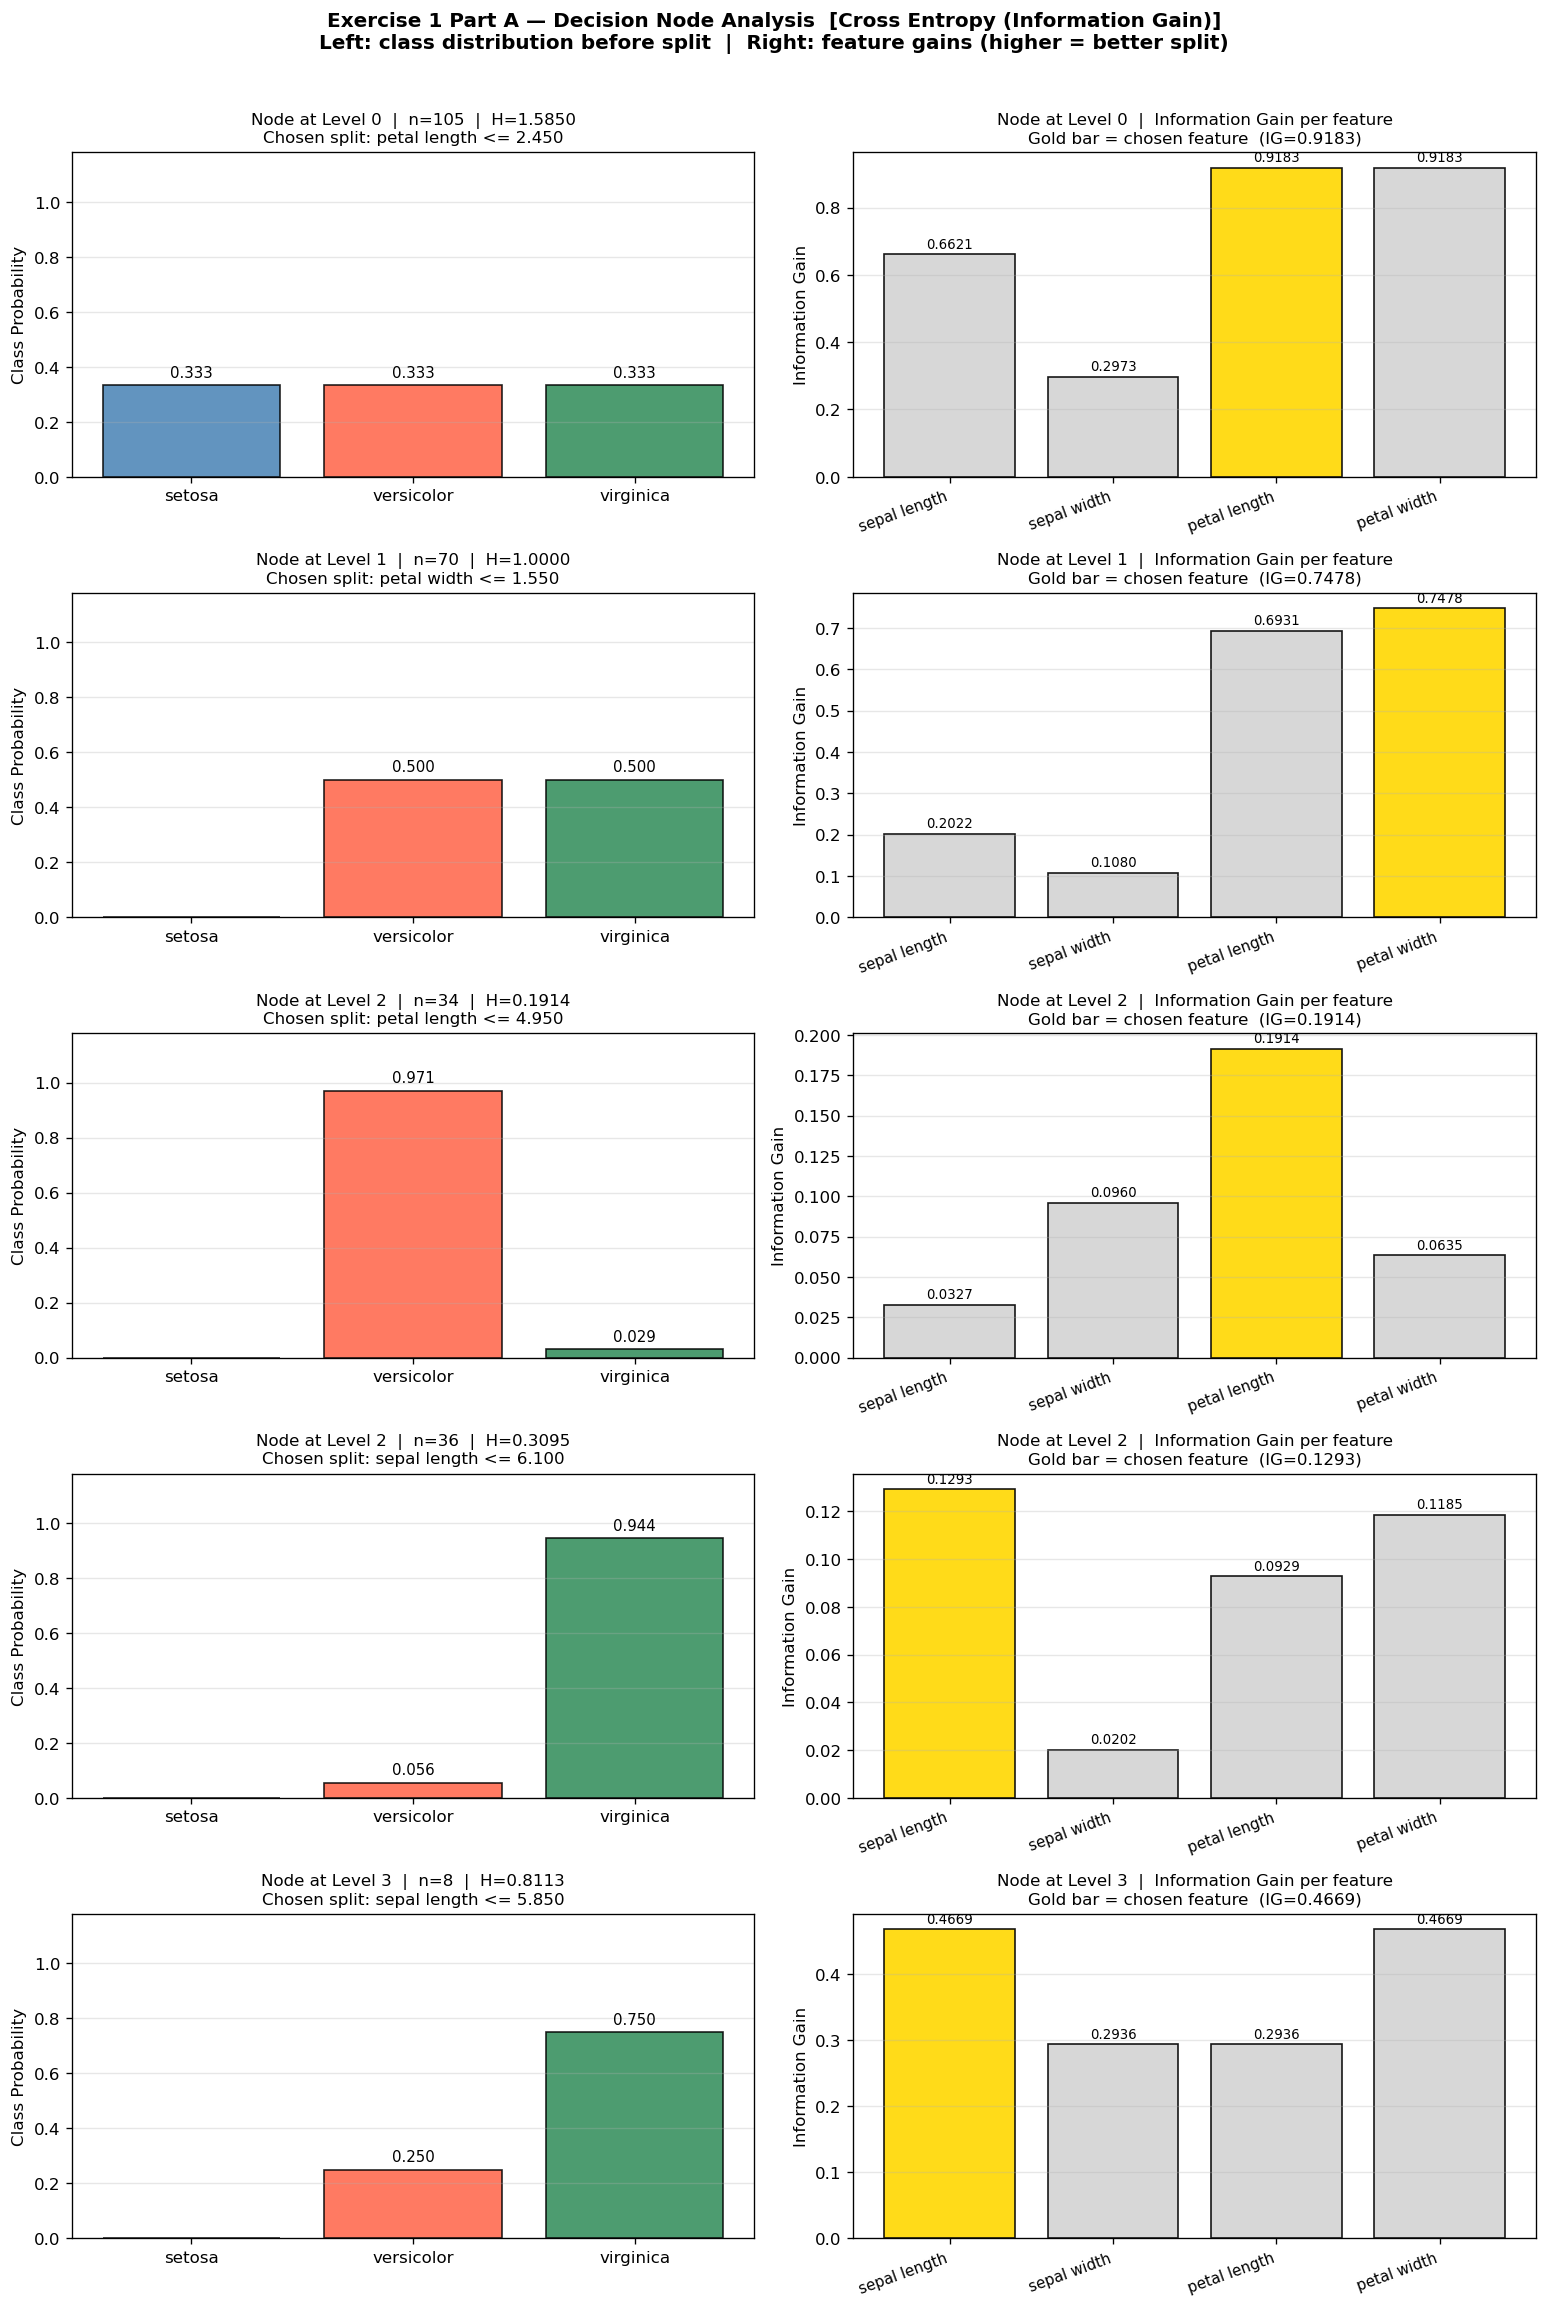

In [10]:
# ── Exercise 1, Part A: Node analysis plots ───────────────────────────────────
#
# Steps 4a and 4b from the exercise:
#   (a) class probabilities histogram at each decision step
#   (b) Cross Entropy of each attribute at each decision step
#
# We show ALL internal nodes (logged during tree building).
# Each row = one decision node.
# Left column  = class probability histogram (how mixed the node is)
# Right column = Information Gain per feature (why we chose that feature)

plot_node_analysis(
    node_log_entropy,
    feature_names, class_names,
    criterion='entropy',
    save_path='fig_ex1_node_analysis_entropy.png'
)

In [11]:
# ── Exercise 1, Part A: Test set evaluation ───────────────────────────────────
#
# Cross Entropy Loss on the test set:
#   CE Loss = -(1/N) Σi log( p_{i, true_class} + eps )
#
# Each test sample reaches a leaf.  That leaf has a class probability vector
# p.  We take the probability assigned to the TRUE class of the sample.
# -log(p) is low when p is close to 1 (confident + correct).
# -log(p) is high when p is close to 0 (model is wrong or uncertain).
#
# We also report accuracy (fraction of correctly classified samples) as a
# more intuitive metric.

print('=== Exercise 1, Part A: Test Set Evaluation ===\n')

proba_test_entropy = predict_proba_all(tree_entropy, X_test)
y_pred_entropy     = predict(tree_entropy, X_test)

loss_entropy = ce_loss(y_test, proba_test_entropy)
acc_entropy  = np.mean(y_pred_entropy == y_test)

print(f'Cross Entropy Loss (test): {loss_entropy:.4f}')
print(f'Accuracy           (test): {acc_entropy:.4f}  '
      f'({int(acc_entropy * len(y_test))}/{len(y_test)} correct)')

print(f'\nPer-class breakdown:')
for k, name in enumerate(class_names):
    mask = y_test == k
    cls_acc  = np.mean(y_pred_entropy[mask] == y_test[mask])
    cls_loss = ce_loss(y_test[mask], proba_test_entropy[mask])
    print(f'  {name:<20}  acc={cls_acc:.3f}  CE loss={cls_loss:.4f}')

print(f'\nSummary table:')
print(f'  Model          | Criterion | CE Loss | Accuracy')
print(f'  {"--"*25}')
print(f'  Entropy tree   | entropy   | {loss_entropy:.4f}  | {acc_entropy:.4f}')

=== Exercise 1, Part A: Test Set Evaluation ===

Cross Entropy Loss (test): 1.5929
Accuracy           (test): 0.9111  (41/45 correct)

Per-class breakdown:
  Iris-setosa           acc=1.000  CE loss=-0.0000
  Iris-versicolor       acc=0.867  CE loss=4.6322
  Iris-virginica        acc=0.867  CE loss=0.1465

Summary table:
  Model          | Criterion | CE Loss | Accuracy
  --------------------------------------------------
  Entropy tree   | entropy   | 1.5929  | 0.9111


=== Building Decision Tree (criterion=gini, max_depth=4) ===

Gini tree:  nodes=13, leaves=7
Gini tree:  CE Loss=2.3180   Accuracy=0.9333
Entropy tree: CE Loss=1.5929  Accuracy=0.9111

Summary table (Exercise 1, Part B):
  Model            | Criterion  | CE Loss   | Accuracy | Nodes | Leaves
  -----------------------------------------------------------------
  Entropy tree     | entropy    | 1.5929    | 0.9111   | 11    | 6
  Gini tree        | gini       | 2.3180    | 0.9333   | 13    | 7


C:\Users\Admin\AppData\Local\Temp\ipykernel_18960\208168505.py:91: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax1.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=7)
C:\Users\Admin\AppData\Local\Temp\ipykernel_18960\208168505.py:106: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax2.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=7)


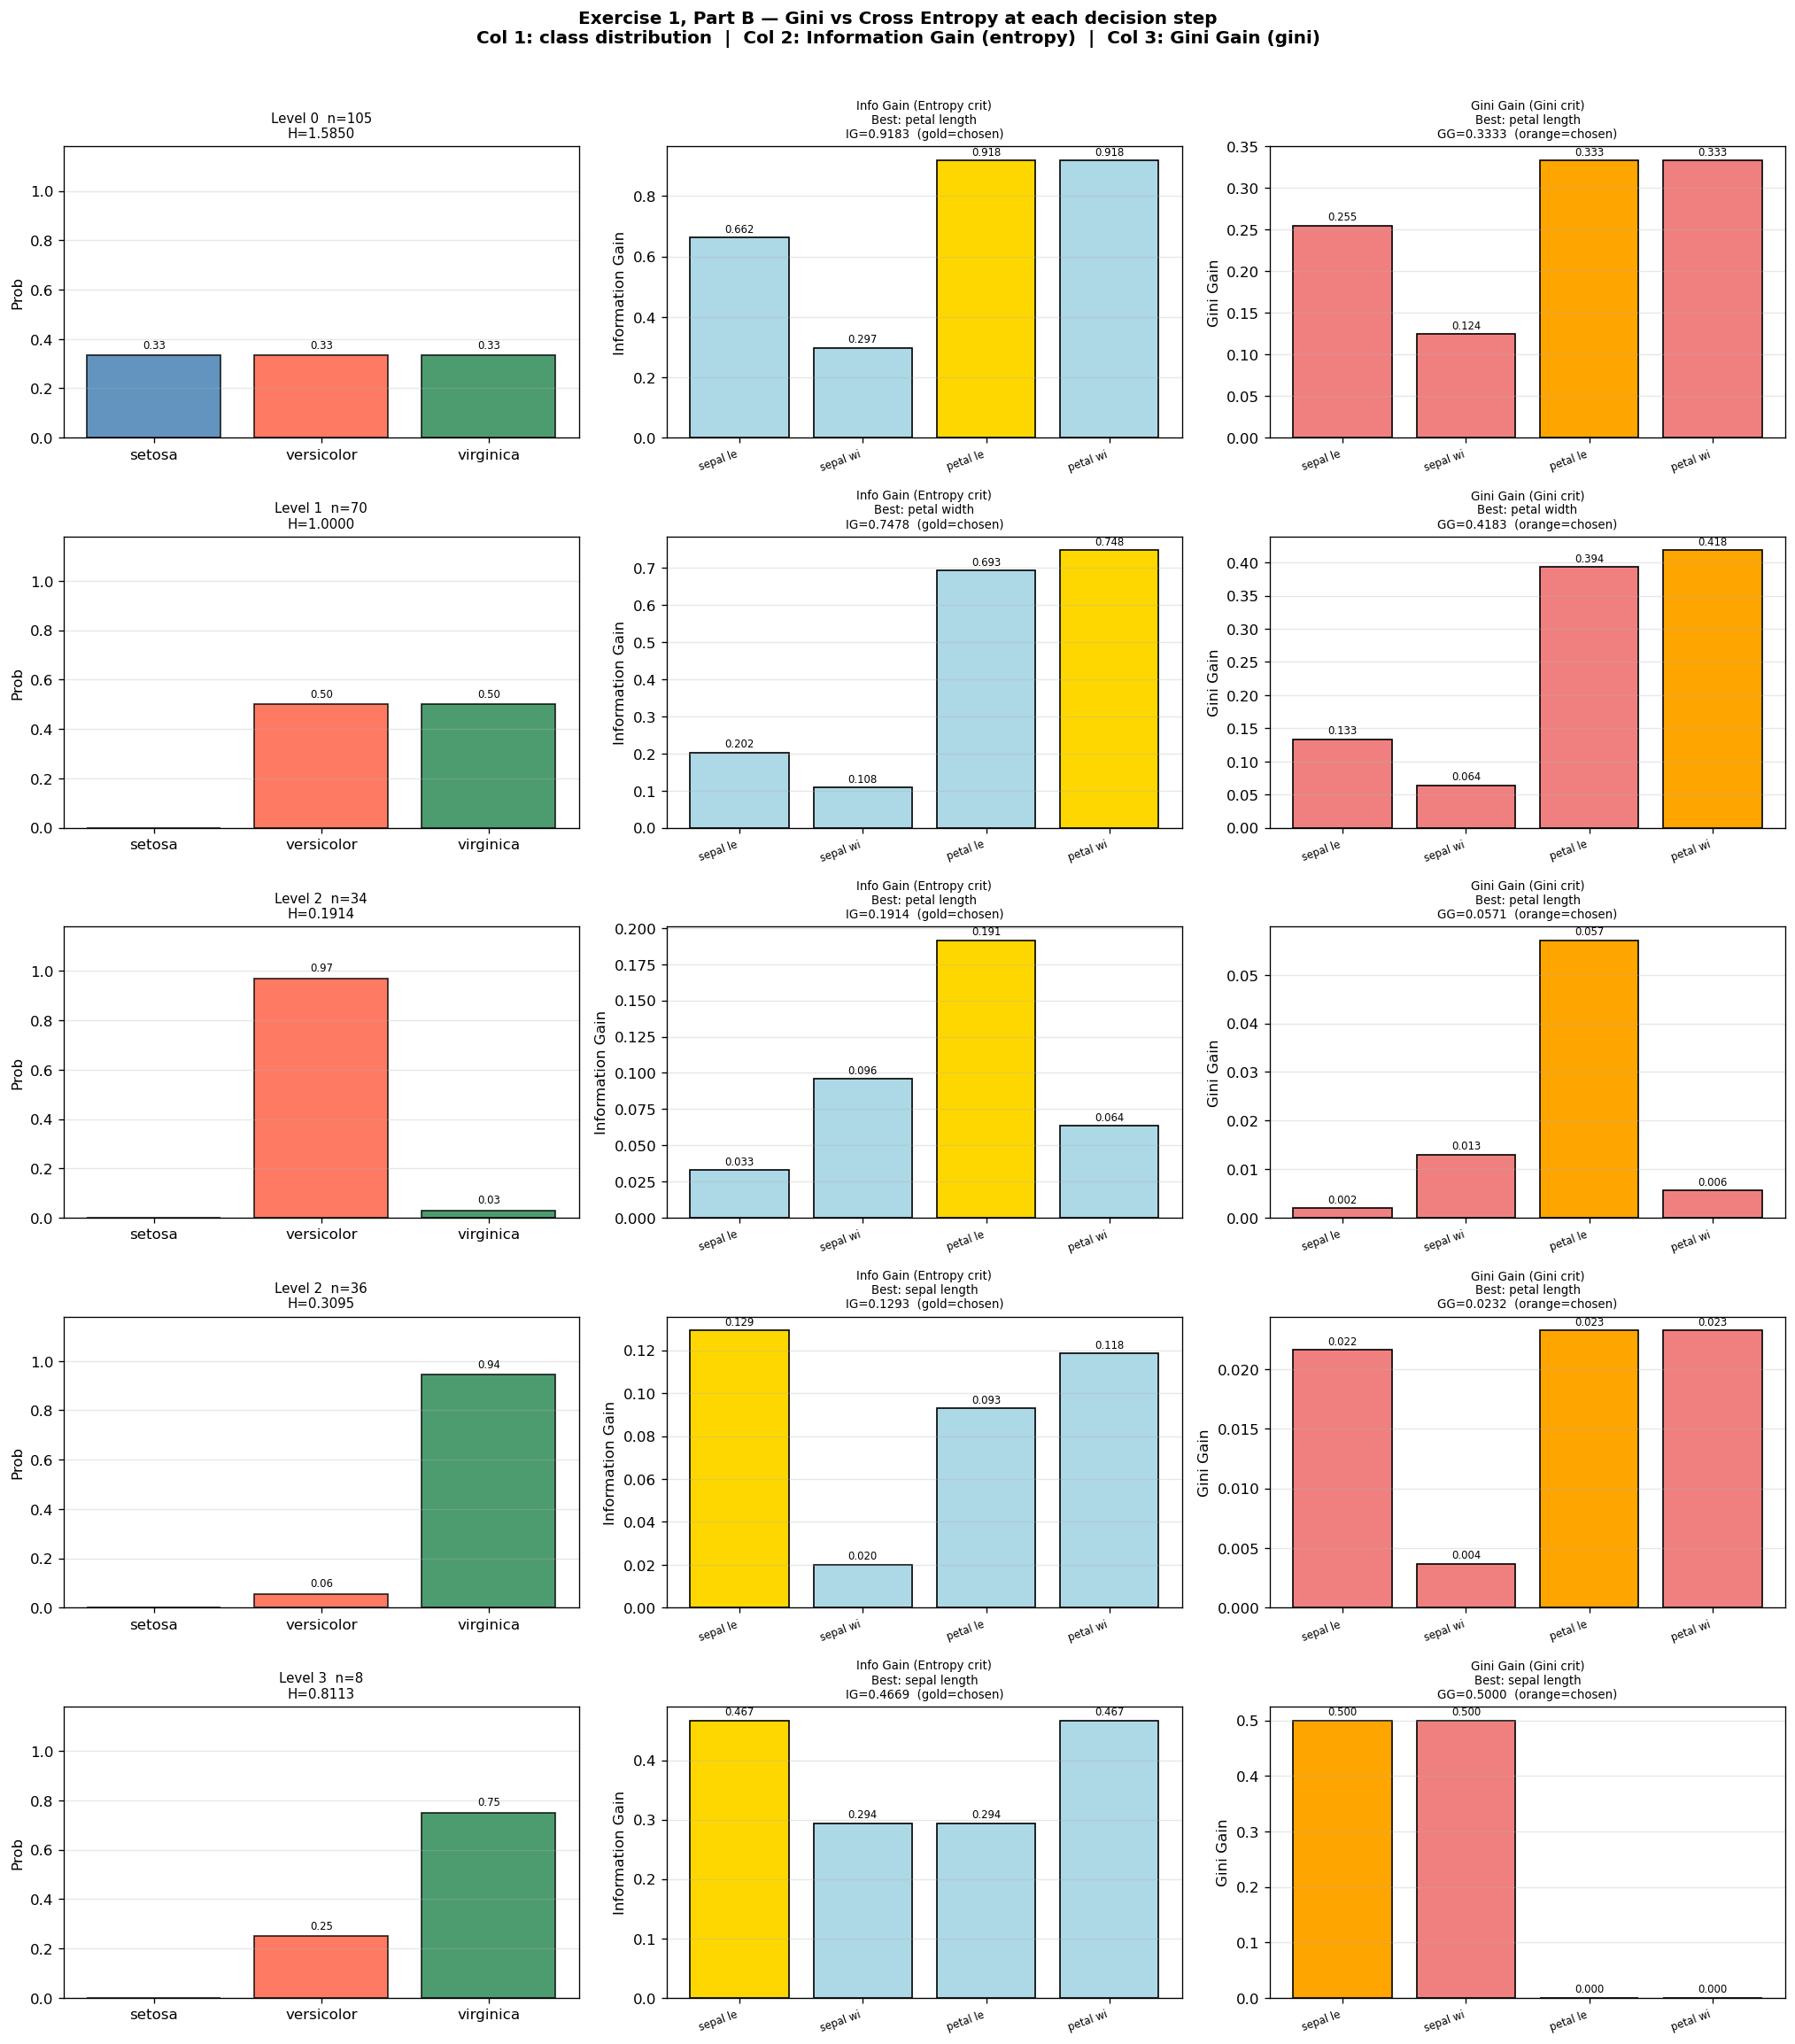

Saved: fig_ex1_gini_comparison.png


In [12]:
# ── Exercise 1, Part B: Gini tree + comparison ────────────────────────────────
#
# We now build the same tree but using Gini Index instead of Cross Entropy.
# Everything else stays identical (same train/test split, same max_depth).
#
# The comparison plot shows THREE columns per node:
#   Col 1: Class probability histogram (same node, same data)
#   Col 2: Information Gain per feature  (from the entropy criterion)
#   Col 3: Gini Gain per feature         (from the gini criterion)
#
# This lets you see:
#   (a) Whether both criteria agree on which feature is best.
#   (b) How the scale of the gain values differs (Gini Gain is smaller
#       in absolute terms than IG, because Gini is bounded by 0.667
#       while entropy can reach 1.585 for 3 classes).

print('=== Building Decision Tree (criterion=gini, max_depth=4) ===\n')

node_log_gini = []
tree_gini = build_tree(
    X_train, y_train, n_classes,
    max_depth=4, min_samples=2, min_gain=1e-7,
    criterion='gini',
    node_log=node_log_gini
)

proba_test_gini = predict_proba_all(tree_gini, X_test)
y_pred_gini     = predict(tree_gini, X_test)
loss_gini       = ce_loss(y_test, proba_test_gini)
acc_gini        = np.mean(y_pred_gini == y_test)

print(f'Gini tree:  nodes={count_nodes(tree_gini)}, leaves={count_leaves(tree_gini)}')
print(f'Gini tree:  CE Loss={loss_gini:.4f}   Accuracy={acc_gini:.4f}')
print(f'Entropy tree: CE Loss={loss_entropy:.4f}  Accuracy={acc_entropy:.4f}')

print(f'\nSummary table (Exercise 1, Part B):')
print(f'  {"Model":<16} | {"Criterion":<10} | {"CE Loss":<9} | {"Accuracy":<8} | Nodes | Leaves')
print(f'  {"-"*65}')
print(f'  {"Entropy tree":<16} | {"entropy":<10} | {loss_entropy:.4f}    | '
      f'{acc_entropy:.4f}   | '
      f'{count_nodes(tree_entropy):<5} | {count_leaves(tree_entropy)}')
print(f'  {"Gini tree":<16} | {"gini":<10} | {loss_gini:.4f}    | '
      f'{acc_gini:.4f}   | '
      f'{count_nodes(tree_gini):<5} | {count_leaves(tree_gini)}')

# ── Comparison plot ───────────────────────────────────────────────────────────
# For each internal node (entropy log vs gini log), plot side-by-side.
# Use the minimum count in case the trees have different numbers of nodes.
n_compare = min(len(node_log_entropy), len(node_log_gini))

node_colors = ['steelblue', 'tomato', 'seagreen']

fig, axes = plt.subplots(n_compare, 3, figsize=(17, 3.8 * n_compare))
if n_compare == 1:
    axes = axes.reshape(1, 3)

for i in range(n_compare):
    e_info = node_log_entropy[i]
    g_info = node_log_gini[i]
    feat_e = e_info['best_feature']
    feat_g = g_info['best_feature']

    short_cls   = [c.replace('Iris-', '') for c in class_names]
    feat_short  = [f[:8] for f in feature_names]

    # Col 0: class histogram
    ax0  = axes[i, 0]
    probs = e_info['class_probs']
    bars = ax0.bar(short_cls, probs,
                   color=[node_colors[k] for k in range(n_classes)],
                   edgecolor='black', alpha=0.85)
    ax0.set_ylim(0, 1.18)
    ax0.set_title(f'Level {e_info["depth"]}  n={e_info["n_samples"]}\n'
                  f'H={e_info["entropy"]:.4f}', fontsize=9)
    ax0.set_ylabel('Prob')
    for bar, p in zip(bars, probs):
        if p > 0.02:
            ax0.text(bar.get_x() + bar.get_width()/2, p + 0.03,
                     f'{p:.2f}', ha='center', fontsize=7)
    ax0.grid(axis='y', alpha=0.3)

    # Col 1: Information Gain (entropy criterion)
    ax1 = axes[i, 1]
    ig_vals = [e_info['all_feature_gains'].get(j, 0) for j in range(4)]
    cols1   = ['gold' if j == feat_e else 'lightblue' for j in range(4)]
    ax1.bar(feat_short, ig_vals, color=cols1, edgecolor='black')
    ax1.set_title(
        f'Info Gain (Entropy crit)\nBest: {feature_names[feat_e][:12]}\n'
        f'IG={e_info["best_gain"]:.4f}  (gold=chosen)', fontsize=8)
    ax1.set_ylabel('Information Gain')
    ax1.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=7)
    ax1.grid(axis='y', alpha=0.3)
    mx = max(ig_vals) if max(ig_vals) > 0 else 1
    for j, v in enumerate(ig_vals):
        ax1.text(j, v + mx * 0.02, f'{v:.3f}', ha='center', fontsize=7)

    # Col 2: Gini Gain (gini criterion)
    ax2 = axes[i, 2]
    gg_vals = [g_info['all_feature_gains'].get(j, 0) for j in range(4)]
    cols2   = ['orange' if j == feat_g else 'lightcoral' for j in range(4)]
    ax2.bar(feat_short, gg_vals, color=cols2, edgecolor='black')
    ax2.set_title(
        f'Gini Gain (Gini crit)\nBest: {feature_names[feat_g][:12]}\n'
        f'GG={g_info["best_gain"]:.4f}  (orange=chosen)', fontsize=8)
    ax2.set_ylabel('Gini Gain')
    ax2.set_xticklabels(feat_short, rotation=20, ha='right', fontsize=7)
    ax2.grid(axis='y', alpha=0.3)
    mx2 = max(gg_vals) if max(gg_vals) > 0 else 1
    for j, v in enumerate(gg_vals):
        ax2.text(j, v + mx2 * 0.02, f'{v:.3f}', ha='center', fontsize=7)

fig.suptitle(
    'Exercise 1, Part B — Gini vs Cross Entropy at each decision step\n'
    'Col 1: class distribution  |  '
    'Col 2: Information Gain (entropy)  |  '
    'Col 3: Gini Gain (gini)',
    fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_ex1_gini_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_ex1_gini_comparison.png')

In [13]:
# ── Exercise 2: Three-way split: 34% train / 33% validation / 33% test ────────
#
# WHY a validation set now?
# Reduced Error Pruning needs a SEPARATE dataset to evaluate pruning decisions.
# We cannot use the test set for this — that would be data leakage (the test set
# should only be touched once, at the very end, to report final performance).
#
# The split is done in two steps:
#   Step 1: hold out 33% as test.  Remaining 67% is (train + val).
#   Step 2: from that 67%, hold out 33% as validation.  The rest (~34%) is train.
#   0.67 * 0.507 ≈ 0.34  and  0.67 * 0.493 ≈ 0.33

print('=== Exercise 2: 34% / 33% / 33% split ===\n')

# Step 1: split off test (33%)
X_tv, X_test2, y_tv, y_test2 = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
# Step 2: split remaining into train (34%) and validation (33%)
# test_size within tv: we want 33% of total = 33/67 ≈ 0.493 of tv
X_train2, X_val, y_train2, y_val = train_test_split(
    X_tv, y_tv, test_size=0.493, random_state=42, stratify=y_tv
)

total = len(X)
print(f'Total samples : {total}')
print(f'Train         : {len(X_train2)} ({len(X_train2)/total:.1%})')
print(f'Validation    : {len(X_val)}   ({len(X_val)/total:.1%})')
print(f'Test          : {len(X_test2)}  ({len(X_test2)/total:.1%})')
print(f'\nTrain  class counts: {np.bincount(y_train2)}')
print(f'Val    class counts: {np.bincount(y_val)}')
print(f'Test   class counts: {np.bincount(y_test2)}')

# ── Build full tree on 34% training set ─────────────────────────────────────
print('\n=== Building tree on 34% training set ===\n')

node_log_ex2 = []
tree_ex2 = build_tree(
    X_train2, y_train2, n_classes,
    max_depth=4, min_samples=2, min_gain=1e-7,
    criterion='entropy',
    node_log=node_log_ex2
)

print(f'Tree before pruning: {count_nodes(tree_ex2)} nodes, '
      f'{count_leaves(tree_ex2)} leaves')

# Baseline: accuracy and CE loss BEFORE pruning (on test set)
proba_ex2_before = predict_proba_all(tree_ex2, X_test2)
acc_ex2_before   = np.mean(predict(tree_ex2, X_test2) == y_test2)
loss_ex2_before  = ce_loss(y_test2, proba_ex2_before)

print(f'\nBEFORE pruning (test set):')
print(f'  CE Loss  = {loss_ex2_before:.4f}')
print(f'  Accuracy = {acc_ex2_before:.4f}')

print('\nTree structure (before pruning):')
print_tree_bfs(tree_ex2, feature_names, class_names)

=== Exercise 2: 34% / 33% / 33% split ===

Total samples : 150
Train         : 50 (33.3%)
Validation    : 50   (33.3%)
Test          : 50  (33.3%)

Train  class counts: [17 16 17]
Val    class counts: [17 17 16]
Test   class counts: [16 17 17]

=== Building tree on 34% training set ===

Tree before pruning: 9 nodes, 5 leaves

BEFORE pruning (test set):
  CE Loss  = 2.0723
  Accuracy = 0.9400

Tree structure (before pruning):
DECISION TREE STRUCTURE  (Breadth-First Traversal)

[Level 0] Root  petal length <= 2.7000
         IG=0.9248  n=50  H=1.5844
         Probs: Iris-setosa=0.340  Iris-versicolor=0.320  Iris-virginica=0.340

  [Level 1] L (feat<=2.700)  LEAF --> Iris-setosa
           n=17  H=0.0000  (pure=True)
           Probs: Iris-setosa=1.000  Iris-versicolor=0.000  Iris-virginica=0.000

  [Level 1] R (feat>2.700)  petal length <= 4.9500
           IG=0.7248  n=33  H=0.9993
           Probs: Iris-setosa=0.000  Iris-versicolor=0.485  Iris-virginica=0.515

    [Level 2] L (feat<=4

In [14]:
# ── Reduced Error Pruning ─────────────────────────────────────────────────────
#
# ALGORITHM:
#   Repeat until no more nodes can be pruned:
#     Collect all internal nodes in post-order (bottom-up: children before parent).
#     For each internal node N:
#       1. Save N's children.
#       2. Make N a leaf (use its majority class as prediction).
#       3. Evaluate accuracy on the VALIDATION set.
#       4. If accuracy >= current best  → keep the prune permanently.
#          Else                         → restore the children.
#
# WHY post-order (bottom-up)?
# We prune the DEEPEST nodes first.  If we tried to prune a high-level node
# first, we would also remove all its children in one go — losing the chance
# to find that some subtrees are good and others are not.
#
# WHY check >= (not >)?
# If accuracy is the same, we prefer the simpler tree (Occam's Razor).
#
# For each pruning decision, the exercise requires us to show:
#   - IG at the parent node (how much this split was contributing)
#   - Collective IG of its children (were the children splits useful?)

def get_postorder_internal(node, result=None):
    """Collect internal nodes in post-order (left, right, node)."""
    if result is None:
        result = []
    if not node.is_leaf:
        get_postorder_internal(node.left,  result)
        get_postorder_internal(node.right, result)
        result.append(node)
    return result

def tree_accuracy(node, X, y):
    return np.mean(predict(node, X) == y)


def prune_tree(root, X_val, y_val, feature_names, class_names):
    """
    Reduced Error Pruning.  Modifies the tree in place.
    Returns the pruned root and a log of all pruning decisions.
    """
    print('=' * 72)
    print('REDUCED ERROR PRUNING')
    print('=' * 72)

    best_val_acc = tree_accuracy(root, X_val, y_val)
    print(f'Before pruning:  val accuracy = {best_val_acc:.4f}')
    print(f'                 nodes        = {count_nodes(root)}')
    print(f'                 leaves       = {count_leaves(root)}')
    print()

    prune_log = []   # record each pruning decision for plotting
    n_pruned  = 0

    improved = True
    while improved:
        improved  = False
        candidates = get_postorder_internal(root)

        for node in candidates:
            if node.is_leaf:
                continue

            # ── Gain info (required by exercise) ────────────────────────────
            parent_gain   = node.info_gain or 0.0
            left_gain     = (node.left.info_gain  or 0.0) if not node.left.is_leaf  else 0.0
            right_gain    = (node.right.info_gain or 0.0) if not node.right.is_leaf else 0.0
            children_gain = left_gain + right_gain

            # ── Save current state ───────────────────────────────────────────
            saved_feat   = node.feature_idx
            saved_thresh = node.threshold
            saved_left   = node.left
            saved_right  = node.right
            saved_ig     = node.info_gain

            # ── Temporarily make a leaf ──────────────────────────────────────
            node.is_leaf      = True
            node.left         = None
            node.right        = None
            node.feature_idx  = None
            node.threshold    = None
            node.info_gain    = None

            new_acc = tree_accuracy(root, X_val, y_val)
            feat_name = feature_names[saved_feat] if saved_feat is not None else '?'

            if new_acc >= best_val_acc:
                # Keep the prune
                print(f'  PRUNED  depth={node.depth}  '
                      f'{feat_name} <= {saved_thresh:.4f}')
                print(f'          Parent IG={parent_gain:.4f}  '
                      f'Children collective IG={children_gain:.4f}')
                print(f'          Val acc: {best_val_acc:.4f} --> {new_acc:.4f}  [kept]')
                prune_log.append({
                    'depth'          : node.depth,
                    'feature'        : feat_name,
                    'threshold'      : saved_thresh,
                    'parent_gain'    : parent_gain,
                    'children_gain'  : children_gain,
                    'acc_before'     : best_val_acc,
                    'acc_after'      : new_acc,
                    'pruned'         : True,
                })
                best_val_acc = new_acc
                n_pruned    += 1
                improved     = True
            else:
                # Restore children
                node.is_leaf     = False
                node.feature_idx = saved_feat
                node.threshold   = saved_thresh
                node.left        = saved_left
                node.right       = saved_right
                node.info_gain   = saved_ig
                print(f'  KEPT    depth={node.depth}  '
                      f'{feat_name} <= {saved_thresh:.4f}')
                print(f'          Parent IG={parent_gain:.4f}  '
                      f'Children collective IG={children_gain:.4f}')
                print(f'          Val acc: {best_val_acc:.4f} --> {new_acc:.4f}  [restored]')
                prune_log.append({
                    'depth'          : node.depth,
                    'feature'        : feat_name,
                    'threshold'      : saved_thresh,
                    'parent_gain'    : parent_gain,
                    'children_gain'  : children_gain,
                    'acc_before'     : best_val_acc,
                    'acc_after'      : new_acc,
                    'pruned'         : False,
                })

    print()
    print(f'Pruning done: {n_pruned} nodes pruned')
    print(f'After pruning: val accuracy = {best_val_acc:.4f}')
    print(f'               nodes        = {count_nodes(root)}')
    print(f'               leaves       = {count_leaves(root)}')
    print('=' * 72)

    return root, prune_log


# ── Run the pruner ────────────────────────────────────────────────────────────
print()
tree_pruned, prune_log = prune_tree(
    tree_ex2, X_val, y_val, feature_names, class_names
)

print('\nTree structure AFTER pruning:')
print_tree_bfs(tree_pruned, feature_names, class_names)


REDUCED ERROR PRUNING
Before pruning:  val accuracy = 0.9600
                 nodes        = 9
                 leaves       = 5

  PRUNED  depth=3  sepal length <= 6.0500
          Parent IG=0.9183  Children collective IG=0.0000
          Val acc: 0.9600 --> 0.9800  [kept]
  KEPT    depth=2  petal width <= 1.6500
          Parent IG=0.3502  Children collective IG=0.0000
          Val acc: 0.9800 --> 0.9600  [restored]
  KEPT    depth=1  petal length <= 4.9500
          Parent IG=0.7248  Children collective IG=0.3502
          Val acc: 0.9800 --> 0.6600  [restored]
  KEPT    depth=0  petal length <= 2.7000
          Parent IG=0.9248  Children collective IG=0.7248
          Val acc: 0.9800 --> 0.3400  [restored]
  KEPT    depth=2  petal width <= 1.6500
          Parent IG=0.3502  Children collective IG=0.0000
          Val acc: 0.9800 --> 0.9600  [restored]
  KEPT    depth=1  petal length <= 4.9500
          Parent IG=0.7248  Children collective IG=0.3502
          Val acc: 0.9800 --> 

=== Exercise 2: Final Evaluation ===

BEFORE pruning  (test):  CE Loss=2.0723  Accuracy=0.9400  Nodes=7
AFTER  pruning  (test):  CE Loss=0.7151  Accuracy=0.9800  Nodes=7


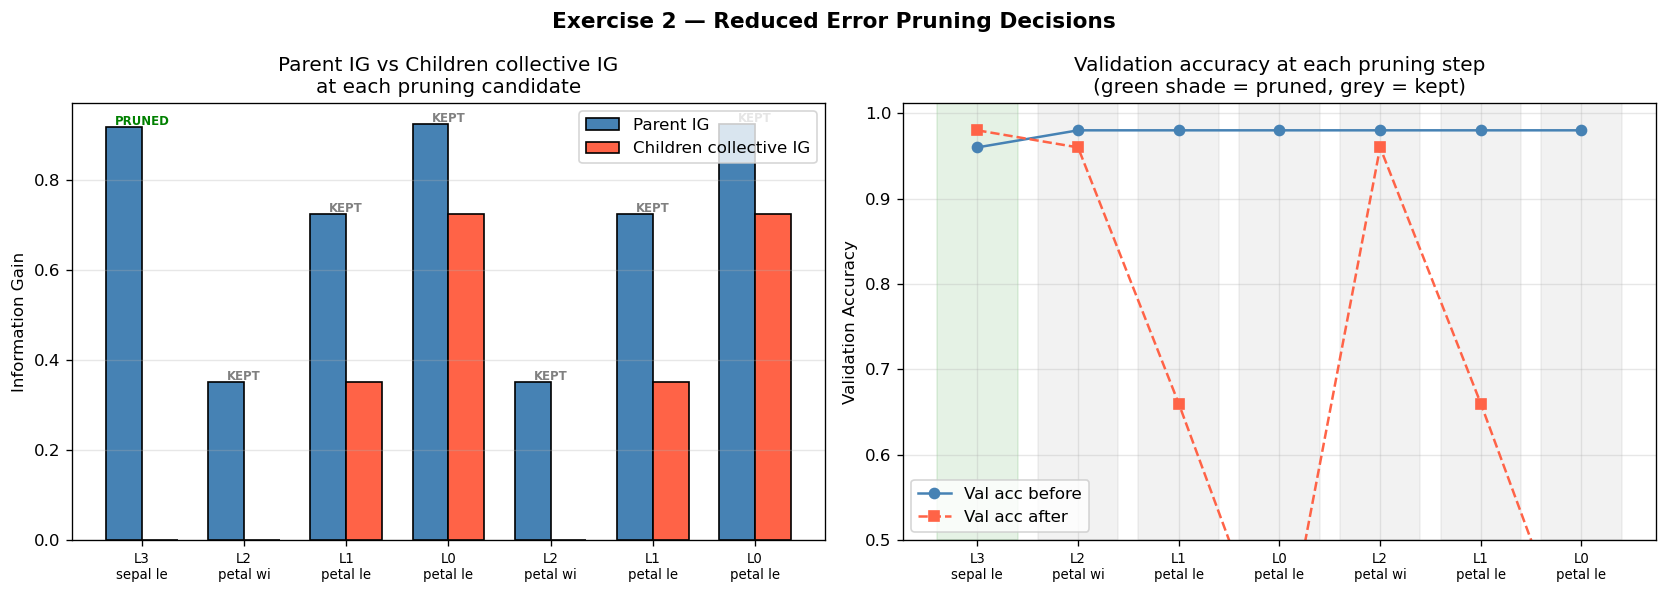

Saved: fig_ex2_pruning.png

=== Final Comparison Across All Experiments ===
Experiment                     | CE Loss   | Accuracy  | Nodes
-----------------------------------------------------------------
Ex1 Entropy tree (70/30)       | 1.5929    | 0.9111    | 11
Ex1 Gini tree (70/30)          | 2.3180    | 0.9333    | 13
Ex2 Before pruning (34/33/33)  | 2.0723    | 0.9400    | 7
Ex2 After pruning  (34/33/33)  | 0.7151    | 0.9800    | 7


In [15]:
# ── Exercise 2: Evaluate pruned tree + compare with Exercise 1 ────────────────

print('=== Exercise 2: Final Evaluation ===\n')

# Evaluate pruned tree on the Exercise 2 test set
proba_ex2_after = predict_proba_all(tree_pruned, X_test2)
y_pred_pruned   = predict(tree_pruned, X_test2)
acc_ex2_after   = np.mean(y_pred_pruned == y_test2)
loss_ex2_after  = ce_loss(y_test2, proba_ex2_after)

print(f'BEFORE pruning  (test):  CE Loss={loss_ex2_before:.4f}  '
      f'Accuracy={acc_ex2_before:.4f}  '
      f'Nodes={count_nodes(tree_ex2) + (0 if not hasattr(tree_ex2, "__pruned") else 0)}')
print(f'AFTER  pruning  (test):  CE Loss={loss_ex2_after:.4f}  '
      f'Accuracy={acc_ex2_after:.4f}  '
      f'Nodes={count_nodes(tree_pruned)}')

# ── Pruning decision plot ─────────────────────────────────────────────────────
# Show parent IG vs children collective IG for each pruning candidate.
# Bars are coloured green (pruned) or grey (kept).

if len(prune_log) > 0:
    n_decisions = len(prune_log)
    labels   = [f'L{d["depth"]}\n{d["feature"][:8]}' for d in prune_log]
    par_igs  = [d['parent_gain']   for d in prune_log]
    chi_igs  = [d['children_gain'] for d in prune_log]
    pruned   = [d['pruned']        for d in prune_log]

    x_pos = np.arange(n_decisions)
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Exercise 2 — Reduced Error Pruning Decisions',
                 fontsize=13, fontweight='bold')

    # Left: parent IG vs children collective IG
    ax0 = axes[0]
    ax0.bar(x_pos - width/2, par_igs, width,
            label='Parent IG', color='steelblue', edgecolor='black')
    ax0.bar(x_pos + width/2, chi_igs, width,
            label='Children collective IG', color='tomato', edgecolor='black')
    for k, (p, c, pr) in enumerate(zip(par_igs, chi_igs, pruned)):
        marker = 'PRUNED' if pr else 'KEPT'
        col    = 'green' if pr else 'grey'
        ax0.text(k, max(p, c) + 0.005, marker,
                 ha='center', fontsize=7, color=col, fontweight='bold')
    ax0.set_xticks(x_pos)
    ax0.set_xticklabels(labels, fontsize=8)
    ax0.set_ylabel('Information Gain')
    ax0.set_title('Parent IG vs Children collective IG\nat each pruning candidate')
    ax0.legend()
    ax0.grid(axis='y', alpha=0.3)

    # Right: val accuracy before and after each decision
    ax1 = axes[1]
    acc_before_list = [d['acc_before'] for d in prune_log]
    acc_after_list  = [d['acc_after']  for d in prune_log]
    ax1.plot(range(n_decisions), acc_before_list,
             'o-', color='steelblue', label='Val acc before')
    ax1.plot(range(n_decisions), acc_after_list,
             's--', color='tomato',    label='Val acc after')
    for k, pr in enumerate(pruned):
        ax1.axvspan(k - 0.4, k + 0.4,
                    alpha=0.1, color='green' if pr else 'grey')
    ax1.set_xticks(range(n_decisions))
    ax1.set_xticklabels(labels, fontsize=8)
    ax1.set_ylabel('Validation Accuracy')
    ax1.set_title('Validation accuracy at each pruning step\n(green shade = pruned, grey = kept)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(bottom=0.5)

    plt.tight_layout()
    plt.savefig('fig_ex2_pruning.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved: fig_ex2_pruning.png')
else:
    print('No pruning decisions were made (tree was already minimal).')

# ── Full comparison table ─────────────────────────────────────────────────────
print()
print('=== Final Comparison Across All Experiments ===')
print(f'{"Experiment":<30} | {"CE Loss":<9} | {"Accuracy":<9} | Nodes')
print('-' * 65)
print(f'{"Ex1 Entropy tree (70/30)":<30} | {loss_entropy:<9.4f} | '
      f'{acc_entropy:<9.4f} | {count_nodes(tree_entropy)}')
print(f'{"Ex1 Gini tree (70/30)":<30} | {loss_gini:<9.4f} | '
      f'{acc_gini:<9.4f} | {count_nodes(tree_gini)}')
print(f'{"Ex2 Before pruning (34/33/33)":<30} | {loss_ex2_before:<9.4f} | '
      f'{acc_ex2_before:<9.4f} | {count_nodes(tree_ex2)}')
print(f'{"Ex2 After pruning  (34/33/33)":<30} | {loss_ex2_after:<9.4f} | '
      f'{acc_ex2_after:<9.4f} | {count_nodes(tree_pruned)}')

In [16]:
# ── Sklearn cross-check ───────────────────────────────────────────────────────
#
# At the end of each exercise we verify our implementation against sklearn.
# Here we use the same max_depth=4 and same train/test split as Exercise 1.
# We expect very similar (not necessarily identical) results because sklearn
# uses optimised C code with the same mathematical criteria.

print('=== Sklearn cross-check (Exercise 1 split, entropy) ===\n')

sk_tree = DecisionTreeClassifier(
    criterion='entropy', max_depth=4, min_samples_split=2, random_state=42
)
sk_tree.fit(X_train, y_train)

sk_proba = sk_tree.predict_proba(X_test)
sk_pred  = sk_tree.predict(X_test)
sk_loss  = ce_loss(y_test, sk_proba)
sk_acc   = accuracy_score(y_test, sk_pred)

print(f'Sklearn tree:  CE Loss={sk_loss:.4f}  Accuracy={sk_acc:.4f}  '
      f'Nodes={sk_tree.tree_.node_count}')
print(f'Our tree:      CE Loss={loss_entropy:.4f}  Accuracy={acc_entropy:.4f}  '
      f'Nodes={count_nodes(tree_entropy)}')

print(f'\nSklearn tree structure:')
print(export_text(sk_tree, feature_names=feature_names))

=== Sklearn cross-check (Exercise 1 split, entropy) ===

Sklearn tree:  CE Loss=1.6173  Accuracy=0.8889  Nodes=11
Our tree:      CE Loss=1.5929  Accuracy=0.9111  Nodes=11

Sklearn tree structure:
|--- petal length <= 2.45
|   |--- class: 0
|--- petal length >  2.45
|   |--- petal width <= 1.55
|   |   |--- petal length <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length >  4.95
|   |   |   |--- class: 2
|   |--- petal width >  1.55
|   |   |--- sepal length <= 6.10
|   |   |   |--- petal width <= 1.85
|   |   |   |   |--- class: 1
|   |   |   |--- petal width >  1.85
|   |   |   |   |--- class: 2
|   |   |--- sepal length >  6.10
|   |   |   |--- class: 2

